# Untangling

`untangle(mesh)` repairs inverted tetrahedra and hexahedra by moving nodes until every corner has a positive signed volume (Escobar et al.'s untangling functional), keeping the connectivity and the boundary, and moving only the nodes near the tangles. See `doc/untangle.md`.

In [1]:
import os

# smooth() below logs one warning per pass; keep the comparison readable.
os.environ.setdefault('MESHIOPLUSPLUS_LOG_LEVEL', 'error')

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

import meshioplusplus as mp


def corner_quality(mesh):
    """The least corner scaled Jacobian of each tetrahedron."""
    t = mesh.cells_dict['tetra']
    p = mesh.points
    e = p[t[:, 1:]] - p[t[:, :1]]
    det = np.linalg.det(e)
    return det / np.prod(np.linalg.norm(e, axis=2), axis=1)


def draw_inverted(ax, mesh, title):
    t = mesh.cells_dict['tetra']
    q = corner_quality(mesh)
    bad = t[q <= 0]
    faces = mesh.points[bad[:, [[0, 1, 2], [0, 1, 3], [0, 2, 3], [1, 2, 3]]]].reshape(-1, 3, 3)
    ax.add_collection3d(Poly3DCollection(faces, facecolor='tab:red', edgecolor='k', lw=0.3, alpha=0.6))
    ax.scatter(*mesh.points.T, s=0.3, c='0.7')
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_zlim(0, 1); ax.set_box_aspect((1, 1, 1)); ax.set_axis_off()
    ax.set_title(f'{title}: {len(bad)} inverted')

## A heavily jittered tetrahedral cube

A fifth of the interior nodes of a 6 000-tetrahedron cube moved at random by 0.08 (its cells are 0.1 across): 486 tetrahedra turn inside out.

{'num_inverted_before': 486, 'num_inverted_after': 0, 'min_quality_before': -0.865482686124685, 'min_quality_after': 0.022706115913533883, 'sweeps': 2, 'moves': 4024}
729 of 1331 nodes moved; connectivity unchanged: True


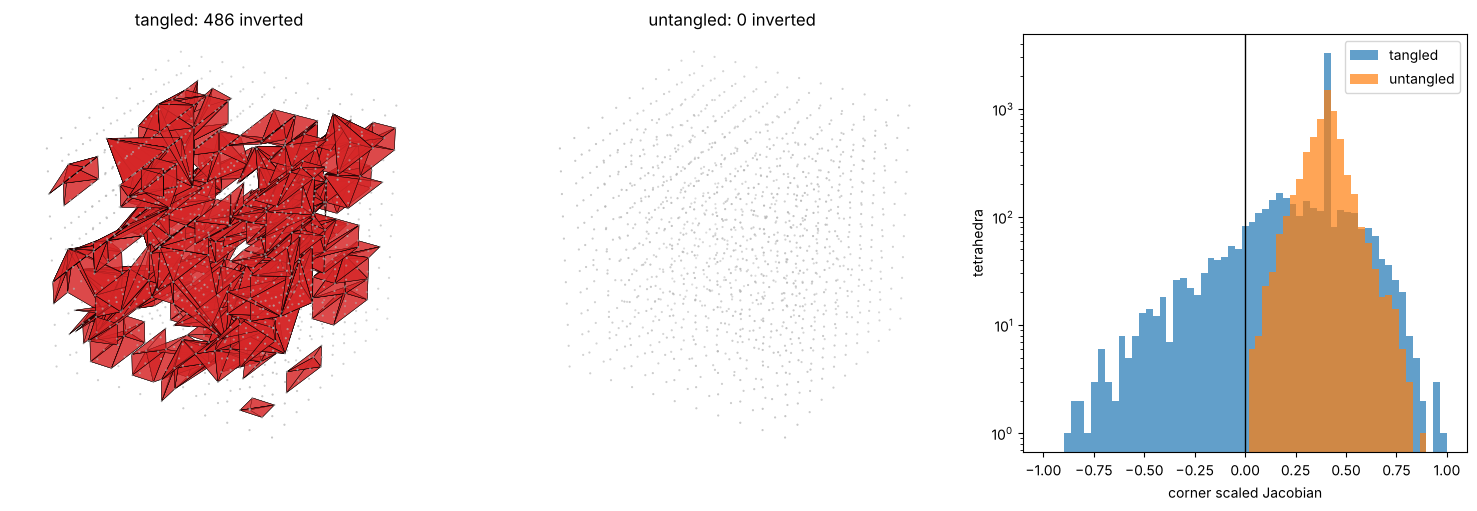

In [2]:
rng = np.random.default_rng(0)
cube = mp.convert_cells(mp.box(dims=(10, 10, 10)), mode='simplexify')
p = cube.points.copy()
interior = np.flatnonzero(np.all((p > 0) & (p < 1), axis=1))
pick = rng.choice(interior, len(interior) // 5, replace=False)
p[pick] += rng.normal(scale=0.08, size=(len(pick), 3))
tangled = mp.Mesh(p, cube.cells)

fixed, report = mp.untangle(tangled, return_report=True)
print(report)
moved = np.abs(fixed.points - tangled.points).max(axis=1) > 0
print(f'{moved.sum()} of {len(p)} nodes moved; connectivity unchanged:',
      np.array_equal(fixed.cells[0].data, tangled.cells[0].data))

fig = plt.figure(figsize=(15, 5))
draw_inverted(fig.add_subplot(1, 3, 1, projection='3d'), tangled, 'tangled')
draw_inverted(fig.add_subplot(1, 3, 2, projection='3d'), fixed, 'untangled')
ax = fig.add_subplot(1, 3, 3)
bins = np.linspace(-1, 1, 60)
ax.hist(corner_quality(tangled), bins=bins, alpha=0.7, label='tangled')
ax.hist(corner_quality(fixed), bins=bins, alpha=0.7, label='untangled')
ax.axvline(0, color='k', lw=1); ax.set_yscale('log')
ax.set_xlabel('corner scaled Jacobian'); ax.set_ylabel('tetrahedra'); ax.legend()
plt.tight_layout()
plt.show()

## Against `smooth` and `optimize_volume`

`smooth`'s inversion guard keeps a valid mesh valid and repairs a tangle only incidentally; `optimize_volume` repairs tetrahedra but flips edges (the connectivity changes) and refuses hexahedra; `untangle` repairs both kinds and keeps the connectivity. `smooth=True` goes on to raise the worst quality.

In [3]:
inverted = lambda m: mp.check_quality(m)['num_inverted']
smoothed = mp.smooth(tangled)
opt = mp.optimize_volume(tangled)
opt = opt[0] if isinstance(opt, tuple) else opt
polished, prep = mp.untangle(tangled, smooth=True, return_report=True)
rows = [
    ('smooth', inverted(smoothed), np.array_equal(smoothed.cells[0].data, tangled.cells[0].data)),
    ('optimize_volume', inverted(opt), np.array_equal(opt.cells[0].data, tangled.cells[0].data)),
    ('untangle', inverted(fixed), True),
    ('untangle(smooth=True)', inverted(polished), True),
]
for name, n, same in rows:
    print(f'{name:>22}: {n:3d} inverted, connectivity kept: {same}')
print(f'least corner scaled Jacobian: untangle {report["min_quality_after"]:.3f}, '
      f'with smooth=True {prep["min_quality_after"]:.3f}')

                smooth:  19 inverted, connectivity kept: True
       optimize_volume:   0 inverted, connectivity kept: False
              untangle:   0 inverted, connectivity kept: True
 untangle(smooth=True):   0 inverted, connectivity kept: True
least corner scaled Jacobian: untangle 0.023, with smooth=True 0.405


## Hexahedra

The centre node of a hexahedral box pushed up by 0.3 folds the corners around it; `untangle` measures every hexahedron corner (Knupp's corner Jacobians) and unfolds them.

{'num_inverted_before': 4, 'num_inverted_after': 0, 'min_quality_before': -1.0, 'min_quality_after': 0.41086964474302096, 'sweeps': 1, 'moves': 432}


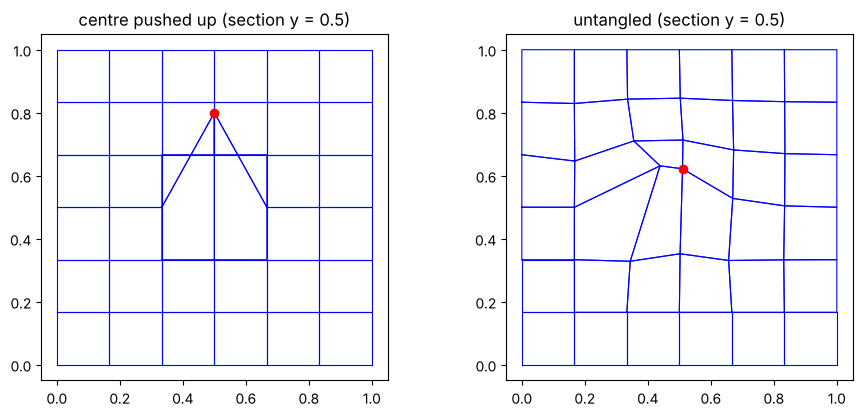

In [4]:
box = mp.box(dims=(6, 6, 6))
q = box.points.copy()
centre = int(np.argmin(np.linalg.norm(q - 0.5, axis=1)))
q[centre] += [0.0, 0.0, 0.3]
hex_fixed, hrep = mp.untangle(mp.Mesh(q, box.cells), return_report=True)
print(hrep)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, pts, title in ((axes[0], q, 'centre pushed up'), (axes[1], hex_fixed.points, 'untangled')):
    sel = np.isclose(box.points[:, 1], 0.5)
    hexes = box.cells_dict['hexahedron']
    inside = np.all(np.isin(hexes[:, [0, 1, 5, 4]], np.flatnonzero(sel)), axis=1)
    for h in hexes[inside][:, [0, 1, 5, 4, 0]]:
        ax.plot(pts[h, 0], pts[h, 2], 'b-', lw=0.8)
    ax.plot(pts[centre, 0], pts[centre, 2], 'ro')
    ax.set_aspect('equal'); ax.set_title(title + ' (section y = 0.5)')
plt.show()

## In a pipeline, and on the command line

The step is `Untangle`; the verb `untangle` in both CLIs.

In [5]:
_, rep = mp.apply_operations(tangled, [{"Op": "Untangle"}])
print(rep['steps'][0])
print('meshioplusplus untangle deformed.vtu fixed.vtu --json')

{'op': 'Untangle', 'NumInvertedBefore': 486.0, 'NumInvertedAfter': 0.0, 'MinQualityAfter': 0.022706115913533883, 'Sweeps': 2.0}
meshioplusplus untangle deformed.vtu fixed.vtu --json
